In [2]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.cm import ScalarMappable
import seaborn as sn
import os
import sys
sys.path.append('..')
from SpikeGLX_Datafile_Tools.Python.DemoReadSGLXData.readSGLX import readMeta,SampRate,makeMemMapRaw,ExtractDigital, GainCorrectIM, GainCorrectNI
import csv
from pathlib import Path
from scipy.signal import correlate

from scipy.ndimage import gaussian_filter
from tqdm import trange

In [10]:
def get_AP_data_map(data_path):

    binFullPath=Path(data_path)
    AP_meta=readMeta(binFullPath)
    AP_sRate=float(AP_meta['imSampRate'])
    AP_datalength=float(AP_meta['fileTimeSecs'])
    
    APdata_map=makeMemMapRaw(binFullPath,AP_meta)
    
    return APdata_map,AP_meta,AP_sRate,AP_datalength

def get_AP_datachunck(AP_data_map,AP_meta,AP_sRate,tStart,tEnd,chanList):
    
    firstSamp=int(tStart*AP_sRate)
    lastSamp=int(tEnd*AP_sRate)
    
    selectData=AP_data_map[chanList,firstSamp:lastSamp+1]
    
    if AP_meta['typeThis'] == 'imec':
        # apply gain correction and convert to uV
        convData = 1e6*GainCorrectIM(selectData, chanList, AP_meta)
    else:
        # apply gain correction and convert to mV
        convData = GainCorrectNI(selectData, chanList, AP_meta)
        
    return convData

In [11]:
import matplotlib as mpl
import matplotlib.pyplot as plt
from matplotlib import font_manager

# Manually create a font property using the full path
arial_font = font_manager.FontProperties(fname='/bucket/ReiterU/common/fonts/arial.ttf')

# Set default font family to use this font
mpl.rcParams['font.family'] = arial_font.get_name()

# Set other style settings
mpl.rcParams.update({
    'font.size': 7,
    'axes.titlesize': 7,
    'legend.fontsize': 7,
    'pdf.fonttype': 42,
    'ps.fonttype': 42,
    'axes.linewidth': 0.5,
    'xtick.major.width': 0.5,
    'xtick.major.size': 2,
    'xtick.minor.size': 2,
    'xtick.minor.width': 0.5,
    'ytick.major.width': 0.5,
    'ytick.minor.width': 0.5,
    'ytick.major.size': 2,
    'ytick.minor.size': 2,
})
mpl.rcParams['font.family'] = arial_font.get_name()


In [13]:
gen_path='/bucket/ReiterU/electrophysiology/squidOL/'
stim_name='DG_LUM'  
exp_name='2024_12_06'
    
rec_string=[item for item in os.listdir(gen_path+exp_name+'/') if stim_name in item][0]
rec_path=gen_path+exp_name+'/'+rec_string
post_path=rec_path+'/post_processed/'
for probe in os.listdir(post_path):
    if len(os.listdir(post_path+'/'+probe))!=0:
        sort_path=post_path+'/'+probe+'/'
        spike_t_matrix=np.load(sort_path+'/spike_t_matrix.npy',allow_pickle=True)
        g_channels=np.load(sort_path+'/g_channels.npy',allow_pickle=True)
        g_ids=np.load(sort_path+'/g_ids.npy',allow_pickle=True)


        lvl1=rec_path+'/raw_data'
        g_file=os.listdir(lvl1)[0]
        if probe=='probe0':
            raw_data_path=lvl1+'/'+g_file+'/'+g_file+'_imec0/'+g_file+'_t0.imec0.ap.bin'

        AP_datamap,AP_meta,AP_sRate,dataLength=get_AP_data_map(raw_data_path)


probe0
nChan: 385, nFileSamp: 99875281


In [14]:
CHOSEN_ID=107

In [15]:
unit_index=np.where(g_ids==CHOSEN_ID)[0][0]
unit_spikes=spike_t_matrix[unit_index]
chosen_spike=unit_spikes[10] # Just chose a spike centre that looks nice
chosen_spike=np.random.choice(unit_spikes)
unit_index=np.where(g_ids==CHOSEN_ID)[0][0]
unit_channel=g_channels[unit_index]
N_channels=60
t_extend=0.020 #seconds
wave_channels=np.arange(unit_channel-int(N_channels/2),unit_channel+int(N_channels/2)+1)

DATACHUNK=get_AP_datachunck(AP_datamap,AP_meta,AP_sRate,chosen_spike-t_extend,chosen_spike+t_extend,wave_channels)
DATACHUNK=DATACHUNK-np.mean(DATACHUNK,axis=0)
DATACHUNK=DATACHUNK-np.median(DATACHUNK,axis=1,keepdims=True)

In [32]:
time_window=0.003
spike_copies=[]
for unit in range(len(g_ids)):

    t_start=chosen_spike-t_extend
    t_end=chosen_spike+t_extend
    spikes=spike_t_matrix[unit]
    unit_copies=[]
    for spike in spikes:
        if spike>t_start and spike<t_end:
            if g_channels[unit] in wave_channels:
                channel_index=np.where(wave_channels==g_channels[unit])[0][0]
                time_index=int((spike-(chosen_spike-t_extend))*AP_sRate)
                t1=time_index-int((time_window/2)*AP_sRate)
                t2=time_index+int((time_window/2)*AP_sRate)
                c1=channel_index-4
                c2=channel_index+4
                spike_copy=np.copy(DATACHUNK)
                mask=np.zeros_like(spike_copy,dtype=bool)
                mask[c1:c2+1,t1:t2+1]=True
                spike_copy[mask==False]=np.nan
                unit_copies.append(spike_copy)
    if len(unit_copies)>0:
        spike_copies.append(unit_copies)
            


In [33]:
the_example = [1049.8698258740847+0.002]
chosen_spike=the_example[0]
t_extend=0.010 #seconds
DATACHUNK=get_AP_datachunck(AP_datamap,AP_meta,AP_sRate,chosen_spike-t_extend,chosen_spike+t_extend,np.arange(0,384))
DATACHUNK=DATACHUNK-np.median(DATACHUNK,axis=0)
DATACHUNK=DATACHUNK-np.mean(DATACHUNK,axis=1,keepdims=True)


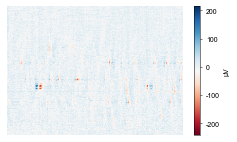

In [34]:
plt.figure(figsize=(10/2.54,6/2.54))
plt.imshow(DATACHUNK[:200],aspect='auto',cmap='RdBu')
plt.axis('off')
cbar=plt.colorbar()
cbar.set_label('μV',fontproperties=arial_font)
cbar.set_ticks([-200,-100,0,+100,+200])
cbar.ax.set_yticklabels([-200,-100,0,100,200], fontproperties=arial_font)
#plt.savefig(save_path+'raw_AP_data.svg',format='svg',dpi=600)
plt.show()

1049.8718258740846


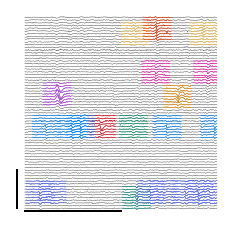

In [35]:
the_example=[1049.8698258740847+0.002]
the_colors=['#009267','#EE0015','#FB9209','#bb3df2','#ff17b9','#ffc94d','#0088ff','#008e80','#5a6ef1','#ed3400','#00cfff','#EE8700']
for i in range(len(the_example)):
    time_window=0.003
    spike_copies=[]
    chosen_spike=the_example[i]
    print(chosen_spike)
    unit_index=np.where(g_ids==CHOSEN_ID)[0][0]
    unit_channel=g_channels[unit_index]
    N_channels=80
    t_extend=0.010 #seconds
    wave_channels=np.arange(unit_channel-int(N_channels/2),unit_channel+int(N_channels/2)+1)

    DATACHUNK=get_AP_datachunck(AP_datamap,AP_meta,AP_sRate,chosen_spike-t_extend,chosen_spike+t_extend,wave_channels)
    DATACHUNK=DATACHUNK-np.mean(DATACHUNK,axis=0)
    DATACHUNK=DATACHUNK-np.median(DATACHUNK,axis=1,keepdims=True)
    units_inside=[]
    for unit in range(len(g_ids)):
        if g_ids[unit] not in [122,327,74]:
            t_start=chosen_spike-t_extend
            t_end=chosen_spike+t_extend
            spikes=spike_t_matrix[unit]
            unit_copies=[]
            for spike in spikes:
                if spike>t_start and spike<t_end:
                    if g_channels[unit] in wave_channels:
                        channel_index=np.where(wave_channels==g_channels[unit])[0][0]
                        time_index=int((spike-(chosen_spike-t_extend))*AP_sRate)
                        t1=time_index-int((time_window/2)*AP_sRate)
                        t2=time_index+int((time_window/2)*AP_sRate)
                        c1=channel_index-4
                        c2=channel_index+4
                        spike_copy=np.copy(DATACHUNK)
                        mask=np.zeros_like(spike_copy,dtype=bool)
                        mask[c1:c2+1,t1:t2+1]=True
                        spike_copy[mask==False]=np.nan
                        unit_copies.append(spike_copy)
            if len(unit_copies)>0:
                spike_copies.append(unit_copies)
                units_inside.append(g_ids[unit])
    width=10/2.54
    height=10/2.54
    x_bar=np.arange(0,0.01*AP_sRate)
    y_bar=np.arange(0,15)
    i=0
    plt.figure(figsize=(width,height))
    for chan in range(10,len(DATACHUNK)):
        plt.plot(range(len(DATACHUNK[0])),DATACHUNK[chan]+chan*120,color='black',alpha=0.8,linewidth=1/2.54)
    for i in range(len(spike_copies)):
        for spike_copy in spike_copies[i]:
            the_color = the_colors[i]
            for chan in range(10,len(spike_copy)):
                plt.plot(range(len(spike_copy[0])),spike_copy[chan]+chan*120,color=the_color,alpha=1,linewidth=1.5/2.54)

    plt.plot(x_bar,np.ones_like(x_bar)+1200-120,c='black',linewidth=2)
    plt.plot(np.ones_like(y_bar)-25,y_bar*120+1200,c='black',linewidth=2)
    plt.axis('off')
    #plt.savefig(save_path+'raw_trace_WITH_KILOSORT.svg',format='svg', dpi=900)
    plt.show()

In [36]:
THE_COLORS=['#EE0015','#FB9209','#bb3df2']

In [37]:
channel_pos=np.load('/bucket/ReiterU/electrophysiology/squidOL/2024_02_15/CONCAT_RECORDING_FILES/probe0/channel_positions.npy')

In [38]:
x_pos_set=np.asarray(sorted(list(set(channel_pos[:,0])))).astype(int)
y_pos_set=np.asarray(sorted(list(set(channel_pos[:,1])))).astype(int)

In [39]:
offset=10
probe_xs=[np.min(x_pos_set)-offset,np.min(x_pos_set)-offset,(np.min(x_pos_set)+np.max(x_pos_set))/2,np.max(x_pos_set)+offset,np.max(x_pos_set)+offset]
probe_ys=[np.max(y_pos_set)+offset,np.min(y_pos_set)-offset,np.min(y_pos_set)-40*offset,np.min(y_pos_set)-offset,np.max(y_pos_set)+offset]

In [40]:
example_ids=[107,116,123]

In [41]:
unit_channel_pos=[]
for unit in range(len(g_channels)):
    unit_channel_pos.append(channel_pos[g_channels[unit]])
unit_channel_pos=np.asarray(unit_channel_pos)

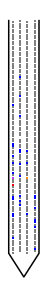

In [43]:

plt.figure(figsize=(1.2/2.54,10/2.54))
plt.plot(probe_xs,probe_ys,color='black',linewidth=1.5)
plt.scatter(channel_pos[:,0],channel_pos[:,1],marker='s',color='gray',s=4,edgecolor='none',antialiased=False)
plt.scatter(unit_channel_pos[:,0],unit_channel_pos[:,1],marker='s',color='blue',s=4,edgecolor='none',antialiased=False)

c=0

for ex in range(len(g_ids)):
    if g_ids[ex] in example_ids:
        plt.scatter(unit_channel_pos[ex,0],unit_channel_pos[ex,1],marker='s',color=THE_COLORS[c],edgecolor='none',s=4,antialiased=False)
        c+=1
        
plt.axis('off')
plt.tight_layout(pad=0.05)
#plt.savefig(save_path+'probe_map.svg',format='svg', dpi=600)

plt.show()

In [ ]:
WAVEFORMS=[]
CHANNELS=[]
SPIKES=[]
GOOD_INDEX=[]
N_spikes=500
time_window=0.003 #seconds
N_channels=14

for unit in trange(len(g_ids)):
        if g_ids[unit] in example_ids:
            waveform,spikes,channels=get_waveform(g_ids[unit],g_ids,g_channels,spike_t_matrix,AP_datamap,N_spikes,time_window,N_channels,AP_sRate,AP_meta)
            WAVEFORMS.append(waveform)
            CHANNELS.append(channels)
            SPIKES.append(spikes)

In [1]:
def get_waveform(unit_id,g_ids,g_channels,spike_matrix,AP_map,N_spikes,time_window,N_channels,AP_sRate,AP_meta):
    
    
    
    
    unit_index=np.where(g_ids==unit_id)[0][0]
    unit_channel=g_channels[unit_index]
    
    if N_spikes>len(spike_matrix[unit_index]):
        N_spikes=len(spike_matrix[unit_index])

    if N_channels>0:
        
        wave_channels=np.arange(unit_channel-int(N_channels/2),unit_channel+int(N_channels/2)+1)
        wave_channels=wave_channels[wave_channels>0] # Avoid errors with neurons right at the tip
    else:
        wave_channels=[unit_channel]
    spike_times=np.random.choice(spike_matrix[unit_index],N_spikes,replace=False)
    spike_waves=[]
    
    
    for spike_t in spike_times:
        firstSamp=int(spike_t*AP_sRate)-int((time_window/2)*AP_sRate)
        lastSamp=int(spike_t*AP_sRate)+int((time_window/2)*AP_sRate)
        spike_snip=AP_map[wave_channels,firstSamp:lastSamp+1]
        spike_snip=1e6*GainCorrectIM(spike_snip, wave_channels, AP_meta)
        spike_snip=spike_snip-np.median(spike_snip,axis=1,keepdims=True)
        spike_waves.append(spike_snip)
    spike_waves=np.asarray(spike_waves)
    spike_waveform=np.mean(spike_waves,axis=0)
    
    
    return spike_waveform,spike_waves,wave_channels
def plot_waveform(waveform,unit_amp,chan_list,chan_pos,unit_id,real_b_channel,to_color,background='False'):
    
    

    X_wave_pos=chan_pos[chan_list]
    X_wave_pos[X_wave_pos==11]=0
    X_wave_pos[X_wave_pos==27]=1
    X_wave_pos[X_wave_pos==43]=2
    X_wave_pos[X_wave_pos==59]=3
    X_wave_pos[:,1]=X_wave_pos[:,1]/20
    X_wave_pos[:,1]=X_wave_pos[:,1]-X_wave_pos[:,1][0]
    WAVE_POS=X_wave_pos.astype('int')
    unit_channel=chan_list[int(len(chan_list)/2)]
    
    do_it=True
    if do_it==True:
        avg_wave=np.mean(waveform,axis=0)

        for i in range(len(avg_wave)):
            avg_wave[i]=avg_wave[i]-np.median(avg_wave[i])

        spike_amp=0
        for i in avg_wave:
            diff=np.max(i)-np.min(i)
            if diff>spike_amp:
                spike_amp=diff
    std_waveform=np.std(waveform,axis=0)
    plt.figure(figsize=(2.6/2.54,2.6/2.54))
    for i in range(len(avg_wave)):
        if chan_list[i]==real_b_channel:
            the_color=to_color
        else:
            the_color='gray'
        x_range=np.arange(0,len(avg_wave[i]))+len(avg_wave[i])*WAVE_POS[i][0]

        if background=='True':
            std_wave_plus=std_waveform[i]+avg_wave[i]
            std_wave_minus=-std_waveform[i]+avg_wave[i]
  
            plt.fill_between(x_range, std_wave_plus+100*WAVE_POS[i][1], std_wave_minus+100*WAVE_POS[i][1], color=the_color, alpha=0.1)

        plt.plot(x_range,avg_wave[i]+100*WAVE_POS[i][1],c=the_color,linewidth=1)
    plt.plot(range(0,30),[np.min(avg_wave)-5]*len(range(0,30)),c='black',linewidth=2)
    plt.plot(np.zeros_like(np.arange(0,100))-15,np.arange(0,100)+np.min(avg_wave)-5,c='black',linewidth=2)

    plt.axis('off')
    plt.savefig(save_path+'unit_waveform{}.svg'.format(unit_channel),format='svg', dpi=600)
    plt.show()

In [103]:
REAL_B_CHANNELS=[]
UNIT_AMPS=[]
for w in range(len(WAVEFORMS)):
    if g_ids[w] in units_inside:
        wave=WAVEFORMS[w]

        spike_amp=0
        b_index=0
        for i in range(len(wave)):
            diff=np.max(wave[i])-np.min(wave[i])
            if diff>spike_amp:
                spike_amp=diff
                b_index=i

        REAL_B_CHANNELS.append(CHANNELS[w][b_index])


        UNIT_AMPS.append(np.round(spike_amp,2))
    else:
        REAL_B_CHANNELS.append(np.nan)
        UNIT_AMPS.append(np.nan)


107


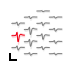

116


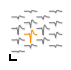

123


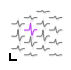

In [108]:
c=0
for unit in range(len(g_ids)):
    if g_ids[unit] in example_ids:
        print(g_ids[unit])
        plot_waveform(SPIKES[unit],UNIT_AMPS[unit],CHANNELS[unit],channel_pos,g_ids[unit],REAL_B_CHANNELS[unit],to_color=THE_COLORS[c],background='True')
        
        c+=1

In [46]:
def autocorrelogram(spikes, bin_size=0.001, max_lag=0.050):
    spike_times = np.array(spikes)
    num_bins = int(2 * max_lag / bin_size) + 1
    autocorr = np.zeros(num_bins, dtype=int)

    for i, t in enumerate(spike_times):
        diffs = spike_times - t
        diffs = diffs[(diffs >= -max_lag) & (diffs <= max_lag)]
        bins = np.round(diffs / bin_size).astype(int)
        autocorr[num_bins//2 + bins] += 1
        autocorr[num_bins//2] = 0


    return autocorr

In [48]:
max_lag=0.02
bin_size=0.001
num_bins = int(2 * max_lag / bin_size) + 1
autocorrs=[]
for unit in range(len(g_ids)):
    if g_ids[unit] in example_ids:
        spike_train=spike_t_matrix[unit]
        autocorr=autocorrelogram(spike_train,bin_size=bin_size,max_lag=max_lag)
        autocorrs.append(autocorr)

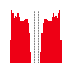

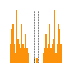

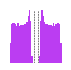

In [49]:
for ex in range(len(autocorrs)):
    plt.figure(figsize=(2.6/2.54,2.6/2.54))
    plt.bar(range(len(autocorrs[ex])),autocorrs[ex],width=1,color=THE_COLORS[ex])
    plt.vlines([(int(len(autocorrs[ex])/2)-1.5),int(len(autocorrs[ex])/2)+1.5],0,np.max(autocorrs[ex]),linestyle='dashed',color='black',linewidth=0.5)
    plt.axis('off')
    #plt.savefig(save_path+'ACC_{}.svg'.format(example_ids[ex]),format='svg', dpi=1200)
    #plt.title(units_inside[ex])
    plt.show()

In [3]:
exp_name='2024_12_06'
probe='0'

In [4]:
###### Loading LFP data ######
binFullPath=Path('/bucket/ReiterU/electrophysiology/squidOL/'+exp_name+'/'+exp_name+'_rec01_STAB_CHECK/raw_data/'+exp_name+'_rec01_STAB_CHECK_g0/'+exp_name+'_rec01_STAB_CHECK_g0_imec'+probe+'/'+exp_name+'_rec01_STAB_CHECK_g0_t0.imec'+probe+'.lf.bin')
binFullPath
chanList=[0]
LFPmeta=readMeta(binFullPath)
LFP_sRate=float(LFPmeta['imSampRate'])
LFPdataLength=float(LFPmeta['fileTimeSecs'])
nChannels=int(LFPmeta['nSavedChans'])
tStart=0
tEnd=int(LFPdataLength) 
firstSamp=int(LFP_sRate*tStart)
lastSamp=int(LFP_sRate*tEnd)
LFPchanList=range(0,nChannels) 

rawData=makeMemMapRaw(binFullPath,LFPmeta)
selectData=rawData[LFPchanList,firstSamp:lastSamp+1]


if LFPmeta['typeThis'] == 'imec':
    # apply gain correction and convert to uV
    convData = 1e6*GainCorrectIM(selectData, LFPchanList, LFPmeta)
else:
    # apply gain correction and convert to mV
    convData = GainCorrectNI(selectData, LFPchanList, LFPmeta)


nChan: 385, nFileSamp: 4927572


In [5]:
def running_median_with_edges(vector,window_size):
    medians = np.zeros(len(vector))

    for i in range(len(vector)):
        start = max(0, i - (window_size - 1) // 2)
        end = min(len(vector), i + (window_size + 1) // 2)
        window = vector[start:end]
        medians[i] = np.median(window)

    return medians


In [6]:
LFPdata=convData[:,::50]
time_axis=np.arange(0,lastSamp)
time_axis=time_axis/LFP_sRate
time_axis=time_axis.astype('int')

In [7]:
LFP_mm = LFPdata- np.mean(LFPdata, axis=1,keepdims=True)
LFP_mm=LFP_mm-np.median(LFP_mm,axis=0)

In [8]:
G_CCs=np.zeros((len(LFP_mm),len(LFP_mm)))
for i in range(len(LFP_mm)):
    for j in range(len(LFP_mm)):
        cc=np.corrcoef(LFP_mm[i],LFP_mm[j])
        G_CCs[i][j]=cc[0][1]

In [9]:
from scipy.ndimage import median_filter

G_CCs_filtered = median_filter(G_CCs, size=(3, 3))

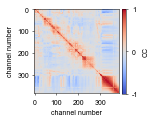

In [14]:

fig = plt.figure(figsize=(5/2.54, 5/2.54))  
im = plt.imshow(G_CCs_filtered[0:384, 0:384], cmap='coolwarm', vmin=-1, vmax=1)

plt.xlabel('channel number', fontproperties=arial_font, fontsize=7)
plt.ylabel('channel number', fontproperties=arial_font, fontsize=7)

plt.xticks([0, 100, 200, 300])
plt.yticks([0, 100, 200, 300])

plt.gca().set_xticklabels([0, 100, 200, 300], fontproperties=arial_font, fontsize=7)
plt.gca().set_yticklabels([0, 100, 200, 300], fontproperties=arial_font, fontsize=7)

# Colorbar
cbar = plt.colorbar(im, fraction=0.046, pad=0.04)
cbar.set_label('CC', fontproperties=arial_font,fontsize=7)
cbar.set_ticks([-1, 0, 1])
cbar.ax.set_yticklabels(['-1', '0', '1'], fontproperties=arial_font,fontsize=7)

plt.tight_layout(pad=0.05)
#fig.savefig(save_path + 'LFP_CCs.svg', format='svg', bbox_inches='tight', pad_inches=0)
plt.show()

